In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import seaborn as sns

# Add the 'src' directory to the system path
src_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
sys.path.insert(0, src_dir)

# Now you can import the module
import standardised_pipeline_utils
from sklearn.preprocessing import MinMaxScaler
from joblib import dump, load
from scipy.stats import pearsonr
from scipy.cluster.hierarchy import fcluster
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import scipy.cluster.hierarchy as sch
from scipy.cluster.hierarchy import dendrogram
from sklearn.metrics import silhouette_score

# Pearson


In [3]:
pearson = load('data/full_pearson100.joblib')
pearson


,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A2ML1-AS1,A2ML1-AS2,A2MP1,A3GALT2,...,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11AP1,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.207437,0.000000,0.365397,0.000000,0.000000,0.0,0.0,0.0,0.166604,...,0.000000,0.000000,0.000000,0.000000,0.0,0.070655,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.089634,0.000000,0.0,0.0,0.0,0.000000,...,-0.098537,0.000000,0.000000,0.000000,0.0,-0.074209,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,0.000000,0.086278,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,0.106925,0.000000,0.000000,0.000000,-0.147446,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.129458,-0.118349,0.098589,0.094037,-0.076360,0.0,0.0,0.0,0.094948,...,0.148686,0.104587,0.101981,0.000000,0.0,0.000000,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.104882,0.000000,-0.075800,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.148775,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,0.000000,-0.164620,0.0,0.0,0.0,0.000000,...,0.157618,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.157165,0.106069


In [4]:
transcriptomics_filtered = load('data/transcriptomics_filtered.joblib')
transcriptomics_filtered

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A4GALT,AAAS,AACS,AACSP1,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
MDAMB468_BREAST,2.689299,2.954196,0.014355,3.329124,0.275007,0.443607,1.575312,5.311430,4.531069,0.056584,...,4.139142,6.986752,2.192194,3.114367,4.250962,2.792855,3.250962,6.233811,3.512227,5.221490
SH4_SKIN,4.980025,3.583760,0.000000,8.405099,0.887525,0.000000,0.111031,5.229972,4.095924,0.070389,...,3.698218,6.113742,1.384050,2.659925,4.979111,0.014355,2.553361,6.644000,3.659925,4.249445
AU565_BREAST,2.518535,2.269033,0.014355,1.275007,0.454176,2.451541,0.933573,6.011898,5.564378,1.618239,...,4.235727,7.373909,0.632268,2.049631,3.471187,0.014355,2.794936,7.776828,3.814550,3.978196
KMRC1_KIDNEY,0.084064,0.070389,0.000000,0.137504,0.000000,0.000000,2.903038,4.842476,3.357552,0.056584,...,4.584361,6.704734,0.432959,1.021480,1.475085,0.485427,1.384050,5.510962,1.263034,3.416840
CAL51_BREAST,4.729553,2.807355,0.014355,0.575312,0.201634,0.713696,3.751678,6.262847,3.874797,0.056584,...,4.835924,7.356496,1.700440,2.424922,3.884598,0.084064,3.558268,6.812113,4.068671,4.939697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FADU_UPPER_AERODIGESTIVE_TRACT,0.070389,0.389567,0.028569,0.028569,0.464668,0.263034,4.168321,5.244887,5.409391,0.189034,...,4.865919,7.543882,0.014355,0.028569,3.807355,0.790772,3.247928,5.279471,4.277241,5.158660
KP4_PANCREAS,0.389567,0.632268,0.042644,0.367371,0.250962,0.150560,2.163499,6.280585,4.335569,0.014355,...,5.210233,6.656067,2.137504,2.558268,3.754888,0.042644,2.912650,6.915401,3.799087,4.475085
MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,3.945795,2.185867,0.014355,0.000000,0.454176,0.070389,0.042644,5.667608,3.218781,0.056584,...,4.143230,7.929318,1.137504,1.835924,4.955127,0.056584,2.107688,5.816856,3.693766,5.030777


In [6]:
# optional: remove genes filtered out in the filtering procedure

In [5]:
# Ensure both datasets are DataFrames
pearson = pearson[transcriptomics_filtered.columns]
pearson

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A4GALT,AAAS,AACS,AACSP1,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.246571,0.207437,0.000000,0.365397,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,...,0.124962,0.000000,0.000000,0.000000,0.000000,0.0,0.206545,0.176568,0.000000,0.000000
AAAS,0.000000,0.000000,0.000000,0.000000,0.089634,0.000000,0.000000,0.000000,-0.160298,0.0,...,-0.078537,-0.098537,0.000000,0.000000,0.000000,0.0,0.000000,0.126028,-0.140422,0.124015
AACS,0.000000,0.000000,0.086278,0.000000,0.000000,0.000000,-0.113664,0.000000,0.470513,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
AAGAB,0.095826,0.106925,0.000000,0.000000,0.000000,-0.147446,-0.121553,0.168963,0.000000,0.0,...,0.191555,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-0.108280,0.235286,0.000000
AAK1,0.141985,0.129458,-0.118349,0.098589,0.094037,-0.076360,0.000000,0.000000,0.000000,0.0,...,0.092193,0.148686,0.104587,0.101981,0.000000,0.0,0.275717,0.300802,0.000000,0.118403
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZRANB2,0.000000,0.000000,-0.104882,0.000000,-0.075800,0.000000,-0.156288,0.190009,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,-0.195975,0.000000,0.186568
ZW10,0.000000,0.000000,0.000000,0.000000,0.148775,0.000000,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.125551,0.000000,0.000000
ZWILCH,0.000000,0.000000,0.000000,0.000000,0.000000,-0.164620,-0.119140,0.155437,0.000000,0.0,...,0.222471,0.157618,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.157165,0.106069


### Pearson Correlations full distribution 

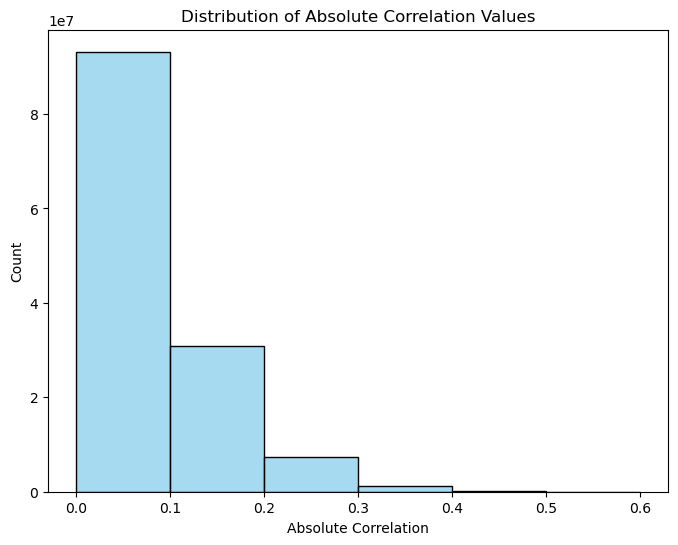

In [8]:
abs_values = pearson.abs().values.flatten()

#bins (0–0.1, 0.1–0.2, 0.2–0.3, ..., 0.9)
bins = np.arange(0, 0.7, 0.1)

plt.figure(figsize=(8, 6))
sns.histplot(abs_values, bins=bins, kde=False, color='skyblue', edgecolor='black')
plt.xlabel('Absolute Correlation')
plt.ylabel('Count')
plt.title('Distribution of Absolute Correlation Values')
plt.xticks(bins)  # Ensure the x-axis shows the bin edges
plt.show()


In [ ]:
data = pearson.values.flatten()

# Create a histogram with a kernel density estimate (KDE) in skyblue
sns.histplot(data, color='skyblue', kde=True)

# Optional customizations
plt.title("Distribution of Pearson Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")

# Display the plot
plt.show()

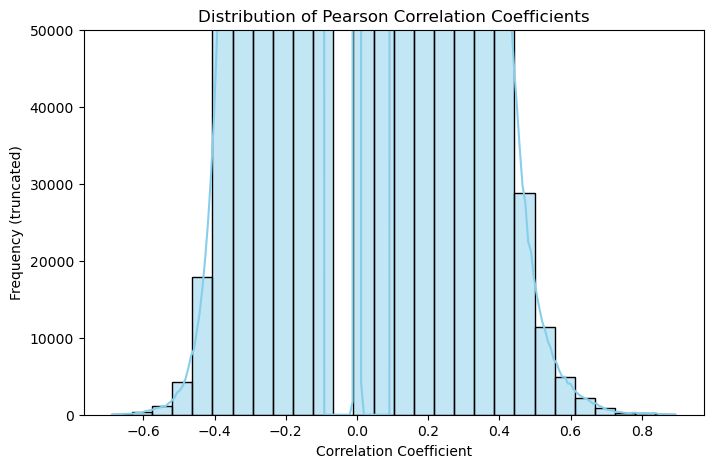

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data, color='skyblue', kde=True)
plt.ylim(top=50000)  # Adjust for zeros
plt.title("Distribution of Pearson Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency (truncated)")
plt.show()

another approach, filter out zeros

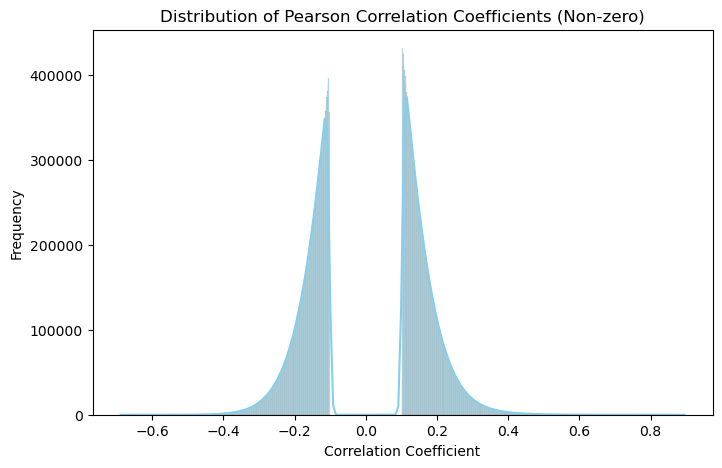

In [ ]:
# Filter out exact zeros or near-zeros
non_zero_data = data[np.isclose(data, 0, atol=1e-10) == False]

plt.figure(figsize=(8, 5))
sns.histplot(non_zero_data, color='skyblue', kde=True)
plt.title("Distribution of Pearson Correlation Coefficients (Non-zero)")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")
plt.show()


### Plot protein - # correlated genes

how many zeros


In [ ]:
zero_counts = (pearson == 0).sum(axis=1)

# Compute the number of genes correlated above thresholds
thresholds = [0.1, 0.2, 0.3]
thresh_counts = {t: (pearson.abs() > t).sum(axis=1) for t in thresholds}

In [ ]:
# Create summary statistics
def print_summary():
    summary = pd.DataFrame({"Zero Correlations": zero_counts})
    for t in thresholds:
        summary[f"Correlated > {t}"] = thresh_counts[t]
    print(summary)

In [ ]:
print_summary()

          Zero Correlations  Correlated > 0.1  Correlated > 0.2  \
proteins                                                          
A2M                   16621              9374              2238   
AAAS                  21095              4900               335   
AACS                  21674              4321               170   
AAGAB                 18766              7229               692   
AAK1                  16124              9871              2548   
...                     ...               ...               ...   
ZRANB2                18648              7347               811   
ZW10                  23115              2880                97   
ZWILCH                18555              7440               705   
ZYX                   17453              8542              1593   
ZZZ3                  18930              7065               701   

          Correlated > 0.3  
proteins                    
A2M                    270  
AAAS                     6  
AACS        

The following histogram displays how many genes per protein have correlations above 0.1 (absolute value). It helps to understand whether most genes have weak or strong correlations with each protein.

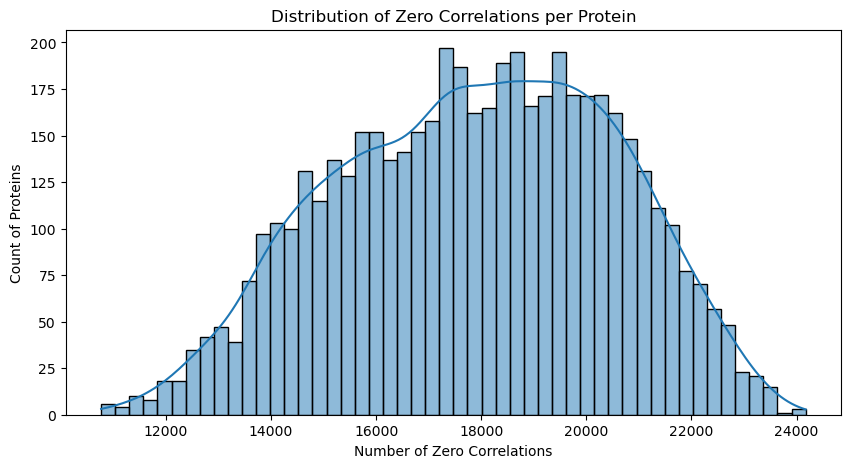

In [ ]:
# Cell 1: Plot histogram of zero counts
plt.figure(figsize=(10, 5))
sns.histplot(zero_counts, bins=50, kde=True)
plt.xlabel("Number of Zero Correlations")
plt.ylabel("Count of Proteins")
plt.title("Distribution of Zero Correlations per Protein")
plt.show()

### Above 0.1 absolute correlation

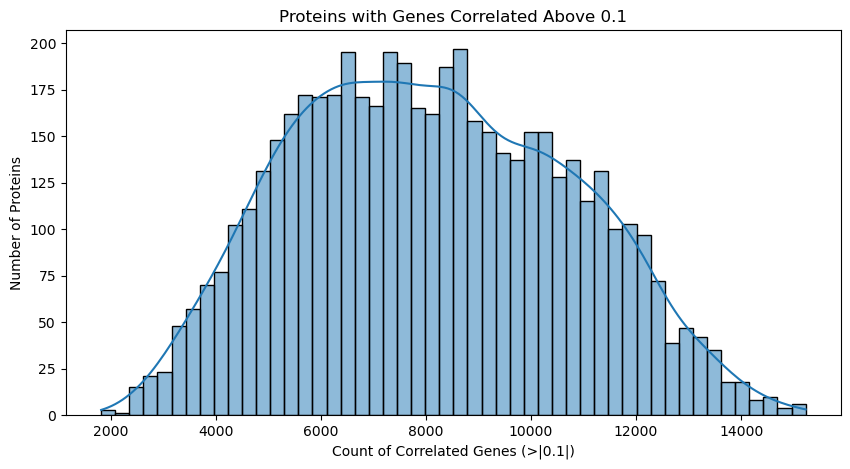

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.1], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.1|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.1")
plt.show()

### Above 0.2 absolute correlation

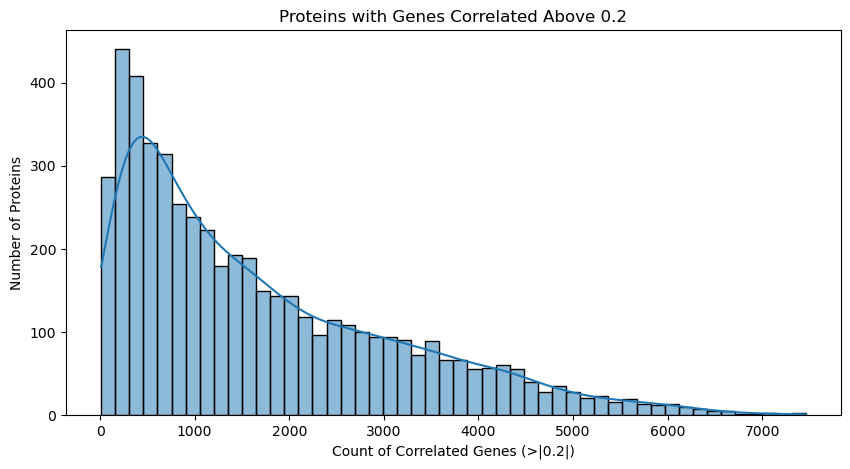

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.2], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.2|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.2")
plt.show()

### Above 0.3 absolute correlation

In [ ]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.3], bins=50, kde=True)
plt.xlabel("Count of Correlated Genes (>|0.3|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.3")
plt.show()

NameError: name 'plt' is not defined

### Clustermap

In [ ]:
#pip install fastcluster

  Obtaining dependency information for fastcluster from https://files.pythonhosted.org/packages/c5/2e/1406301a131605cd27cbdca56c81e59475433d5145fd05759f06cff5717c/fastcluster-1.2.6-cp311-cp311-win_amd64.whl.metadata
Note: you may need to restart the kernel to use updated packages.


Shape after cleaning: (5113, 25976)


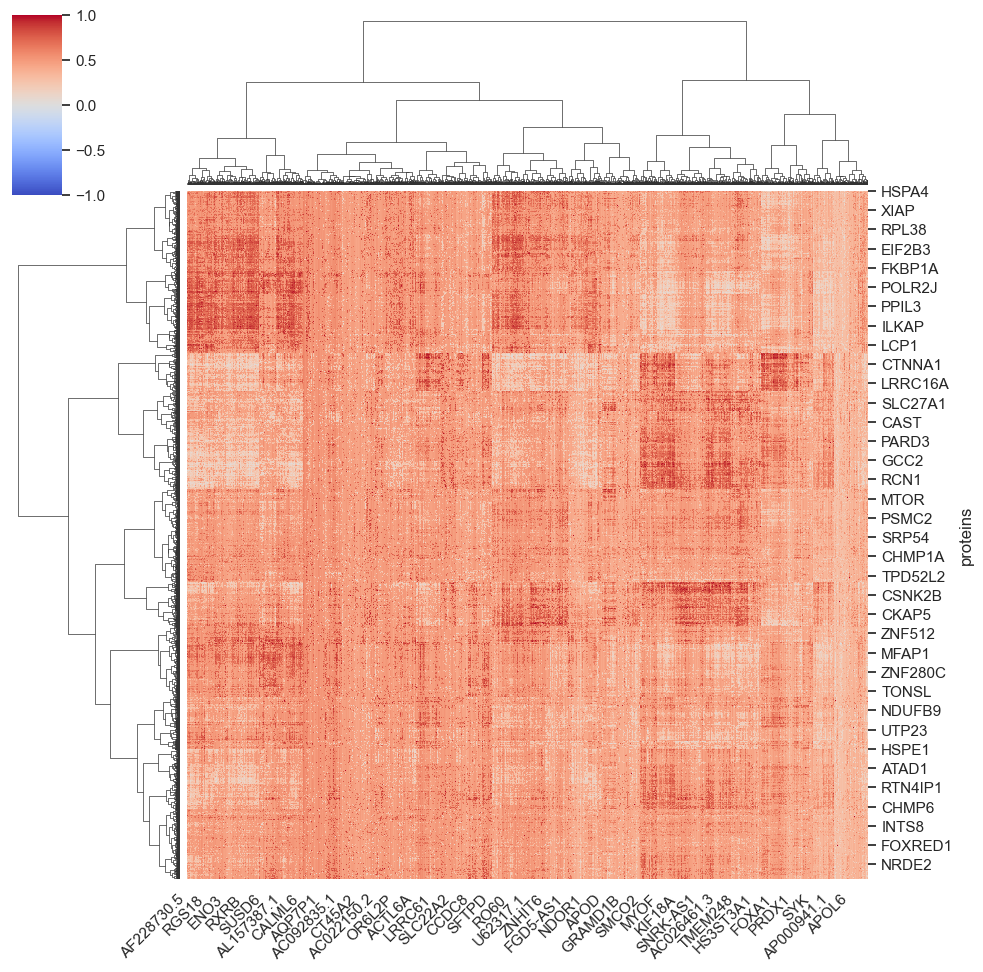

In [6]:
# 1. Replace infinite values with NaN.
pearson_clean = pearson.replace([np.inf, -np.inf], np.nan)

# 2. Drop rows and columns with NaN values.
pearson_clean = pearson_clean.dropna(axis=0, how='any').dropna(axis=1, how='any')

# 3. Drop rows and columns with zero variance to avoid division-by-zero issues.
pearson_clean = pearson_clean.loc[pearson_clean.var(axis=1) != 0, :]
pearson_clean = pearson_clean.loc[:, pearson_clean.var(axis=0) != 0]

# Optional: Print shapes to ensure cleaning worked.
print("Shape after cleaning:", pearson_clean.shape)

# 4. Create the clustermap.
sns.set_theme(style="white")
g = sns.clustermap(
    pearson_clean,
    method="ward",         # Clustering method
    metric="euclidean",    # Distance metric
    cmap="coolwarm",           # Color map for correlation data
    center=0,              # Center the colormap at zero
    vmin=-1, vmax=1,       # Expected correlation range
    standard_scale=1,      # Standardize each row (protein)
    figsize=(10, 10)       # Figure size
)

# 5. Rotate x-axis labels for readability.
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha="right")
plt.show()


In [7]:
def plot_dendrogram(linkage_matrix, threshold=None):
    """Plots the dendrogram and suggests the number of clusters based on visual gap."""
    plt.figure(figsize=(10, 5))
    dendrogram(linkage_matrix)
    if threshold:
        plt.axhline(y=threshold, color='r', linestyle='--')
    plt.xlabel("Proteins")
    plt.ylabel("Cluster Distance")
    plt.title("Dendrogram for Hierarchical Clustering")
    plt.show()


In [8]:
def elbow_method(pearson_clean, linkage_matrix, k_range=(2, 15)):
    """Computes the Elbow Method to find optimal clusters."""
    wcss = []
    for k in range(k_range[0], k_range[1]):
        labels = sch.fcluster(linkage_matrix, k, criterion='maxclust')
        cluster_var = sum(np.var(pearson_clean[labels == i], axis=0).sum() for i in np.unique(labels))
        wcss.append(cluster_var)

    # Find the "elbow" (biggest drop in variance)
    diffs = np.diff(wcss)  # First derivative
    elbow_k = k_range[0] + np.argmin(diffs)  # Best k is where WCSS drops the most

    # Plot the elbow curve
    plt.figure(figsize=(8, 4))
    plt.plot(range(k_range[0], k_range[1]), wcss, marker='o', label="WCSS")
    plt.axvline(x=elbow_k, color='r', linestyle='--', label=f"Elbow at k={elbow_k}")
    plt.xlabel("Number of Clusters")
    plt.ylabel("Within-cluster Variance (WCSS)")
    plt.title("Elbow Method for Optimal Clusters")
    plt.legend()
    plt.show()

    return elbow_k



In [9]:
def silhouette_method(pearson_clean, linkage_matrix, k_range=(2, 15)):
    """Computes the best number of clusters using the Silhouette Score."""
    best_k = k_range[0]
    best_score = -1

    for k in range(k_range[0], k_range[1]):
        labels = sch.fcluster(linkage_matrix, k, criterion='maxclust')
        score = silhouette_score(pearson_clean, labels, metric='euclidean')

        if score > best_score:
            best_score = score
            best_k = k

    return best_k

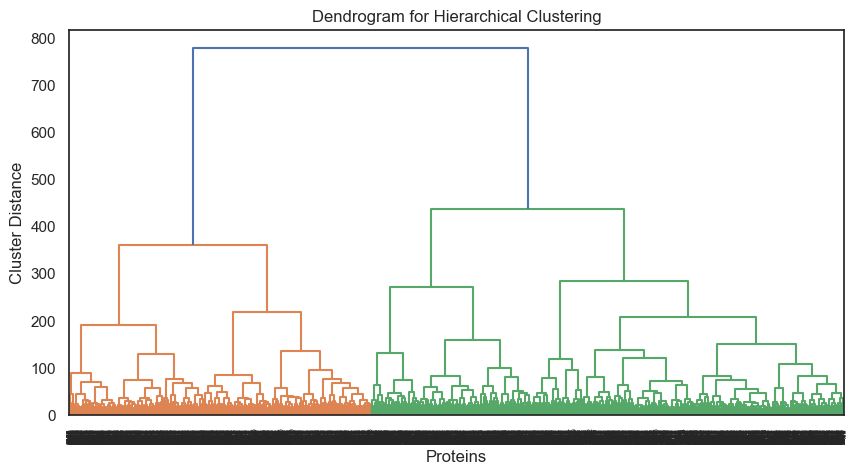

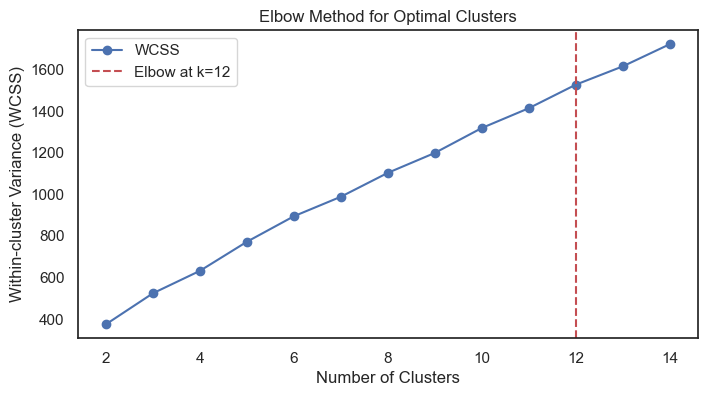

In [10]:
# Generate the hierarchical linkage matrix from the cleaned Pearson matrix
row_linkage = sch.linkage(pearson_clean, method="ward", metric="euclidean")

# 1. Dendrogram Method (Manual Inspection Required)
plot_dendrogram(row_linkage)  # Visually inspect and manually choose a number

# 2. Elbow Method
elbow_k = elbow_method(pearson_clean, row_linkage)

# 3. Silhouette Score Method
silhouette_k = silhouette_method(pearson_clean, row_linkage)


#### number of clusters according to elbow score

In [11]:
# ------------------------------
# Extracting Cluster Assignments
# ------------------------------

# The row dendrogram linkage is stored in g.dendrogram_row.linkage.
row_linkage = g.dendrogram_row.linkage

# Choose a criterion for forming flat clusters. Here we use a maximum of 4 clusters.
# You can change max_clusters or use a distance threshold with criterion='distance'
max_clusters = elbow_k
cluster_labels = fcluster(row_linkage, max_clusters, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_elbow.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters.csv'.")




Protein Clusters:
     Protein  Cluster
0        A2M        8
1       AAAS       12
2       AACS        6
3      AAGAB        1
4       AAK1        4
...      ...      ...
5108  ZRANB2        2
5109    ZW10        6
5110  ZWILCH        1
5111     ZYX        8
5112    ZZZ3        9

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters.csv'.


#### number of clusters according to silhouette score

In [12]:
max_clusters = silhouette_k
cluster_labels = fcluster(row_linkage, max_clusters, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_sil.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters.csv'.")


Protein Clusters:
     Protein  Cluster
0        A2M        2
1       AAAS        2
2       AACS        2
3      AAGAB        1
4       AAK1        2
...      ...      ...
5108  ZRANB2        1
5109    ZW10        2
5110  ZWILCH        1
5111     ZYX        2
5112    ZZZ3        2

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters.csv'.


In [13]:
optimal_k = 2

# Assign each protein to a cluster
clusters = sch.fcluster(row_linkage, optimal_k, criterion="maxclust")

# Convert to DataFrame
cluster_df = pd.DataFrame({"Protein": pearson_clean.index, "Cluster": clusters})

# Count how many proteins per cluster
cluster_sizes = cluster_df["Cluster"].value_counts().sort_index()

print(cluster_sizes)

Cluster
1    1206
2    3907
Name: count, dtype: int64


Measures cluster compactness, lower is better, with 5 clusters was 990

In [14]:
wcss = sum(np.var(pearson_clean[clusters == i], axis=0).sum() for i in np.unique(clusters))
print("Within-Cluster Variance:", wcss)


Within-Cluster Variance: 365.25880432128906


Checks how well clusters are separated closer to 1.0 means clear separation, with 5 clusters was 0.06

In [15]:
sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')
print("Silhouette Score:", sil_score)

Silhouette Score: 0.18693167


Try with different number of clusters to se the best


Clusters: 2
Cluster Sizes: {1: 1206, 2: 3907}
Within-Cluster Variance (WCSS): 365.2588
Silhouette Score: 0.1869
Dunn Index: 0.1470
Calinski-Harabasz Index: 1286.0191
Davies-Bouldin Index: 1.5736

Clusters: 3
Cluster Sizes: {1: 1206, 2: 1009, 3: 2898}
Within-Cluster Variance (WCSS): 528.7393
Silhouette Score: 0.1187
Dunn Index: 0.1586
Calinski-Harabasz Index: 1067.0005
Davies-Bouldin Index: 2.0188

Clusters: 4
Cluster Sizes: {1: 1206, 2: 1009, 3: 1021, 4: 1877}
Within-Cluster Variance (WCSS): 664.8080
Silhouette Score: 0.1017
Dunn Index: 0.1788
Calinski-Harabasz Index: 891.8374
Davies-Bouldin Index: 2.1838

Clusters: 5
Cluster Sizes: {1: 1206, 2: 1009, 3: 1021, 4: 527, 5: 1350}
Within-Cluster Variance (WCSS): 758.4897
Silhouette Score: 0.0711
Dunn Index: 0.1788
Calinski-Harabasz Index: 775.2681
Davies-Bouldin Index: 2.2847

Clusters: 6
Cluster Sizes: {1: 1206, 2: 283, 3: 726, 4: 1021, 5: 527, 6: 1350}
Within-Cluster Variance (WCSS): 886.2427
Silhouette Score: 0.0739
Dunn Index: 0.1788


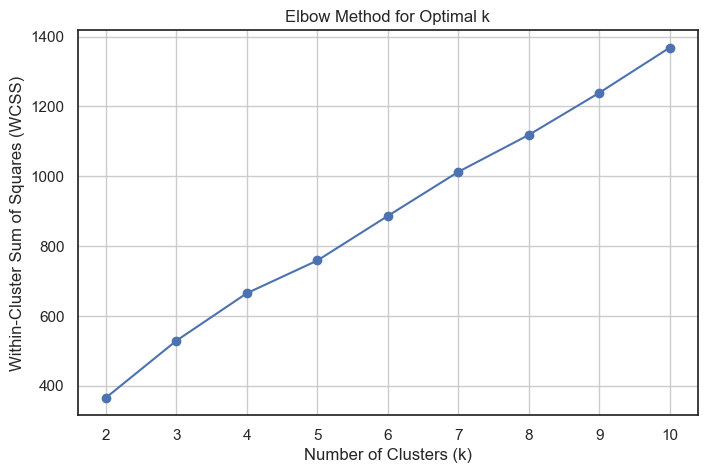

In [16]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.spatial.distance import pdist, squareform

# Function to compute Dunn Index
def dunn_index(data, labels):
    distances = squareform(pdist(data, metric="euclidean"))
    unique_clusters = np.unique(labels)
    
    intercluster_distances = np.min([
        np.min(distances[labels == i][:, labels == j]) 
        for i in unique_clusters for j in unique_clusters if i != j
    ])
    
    intracluster_distances = np.max([
        np.max(distances[labels == i][:, labels == i]) 
        for i in unique_clusters
    ])
    
    return intercluster_distances / intracluster_distances

# Define range of cluster sizes
k_range = range(2, 11)

# Store results
results = []
wcss_values = []  # For the elbow method

for k in k_range:
    # Assign each protein to a cluster
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")

    # Convert to DataFrame
    cluster_df = pd.DataFrame({"Protein": pearson_clean.index, "Cluster": clusters})

    # Count proteins per cluster
    cluster_sizes = cluster_df["Cluster"].value_counts().sort_index()

    # Compute Within-Cluster Variance (WCSS)
    wcss = sum(np.var(pearson_clean[clusters == i], axis=0).sum() for i in np.unique(clusters))
    wcss_values.append(wcss)  # Store WCSS for elbow method

    # Compute Silhouette Score
    sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')

    # Compute Dunn Index
    dunn = dunn_index(pearson_clean.values, clusters)

    # Compute Calinski-Harabasz Index
    calinski_harabasz = calinski_harabasz_score(pearson_clean, clusters)

    # Compute Davies-Bouldin Index
    davies_bouldin = davies_bouldin_score(pearson_clean, clusters)

    # Store results
    results.append((k, cluster_sizes.to_dict(), wcss, sil_score, dunn, calinski_harabasz, davies_bouldin))

# Print results
for k, sizes, wcss, sil_score, dunn, calinski_harabasz, davies_bouldin in results:
    print(f"\nClusters: {k}")
    print(f"Cluster Sizes: {sizes}")
    print(f"Within-Cluster Variance (WCSS): {wcss:.4f}")
    print(f"Silhouette Score: {sil_score:.4f}")
    print(f"Dunn Index: {dunn:.4f}")
    print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")
    print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")

# Elbow Method Plot
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss_values, marker='o', linestyle='-')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.title("Elbow Method for Optimal k")
plt.xticks(k_range)
plt.grid()
plt.show()


In [17]:
# Define range of cluster sizes
k_range = range(2, 11)

# Store results
results = []

for k in k_range:
    # Assign each protein to a cluster
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")

    # Convert to DataFrame
    cluster_df = pd.DataFrame({"Protein": pearson_clean.index, "Cluster": clusters})

    # Count proteins per cluster
    cluster_sizes = cluster_df["Cluster"].value_counts().sort_index()

    # Compute Within-Cluster Variance (WCSS)
    wcss = sum(np.var(pearson_clean[clusters == i], axis=0).sum() for i in np.unique(clusters))

    # Compute Silhouette Score
    sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')

    # Store results
    results.append((k, cluster_sizes.to_dict(), wcss, sil_score))

# Print results
for k, sizes, wcss, sil_score in results:
    print(f"\nClusters: {k}")
    print(f"Cluster Sizes: {sizes}")
    print(f"Within-Cluster Variance (WCSS): {wcss:.4f}")
    print(f"Silhouette Score: {sil_score:.4f}")



Clusters: 2
Cluster Sizes: {1: 1206, 2: 3907}
Within-Cluster Variance (WCSS): 365.2588
Silhouette Score: 0.1869

Clusters: 3
Cluster Sizes: {1: 1206, 2: 1009, 3: 2898}
Within-Cluster Variance (WCSS): 528.7393
Silhouette Score: 0.1187

Clusters: 4
Cluster Sizes: {1: 1206, 2: 1009, 3: 1021, 4: 1877}
Within-Cluster Variance (WCSS): 664.8080
Silhouette Score: 0.1017

Clusters: 5
Cluster Sizes: {1: 1206, 2: 1009, 3: 1021, 4: 527, 5: 1350}
Within-Cluster Variance (WCSS): 758.4897
Silhouette Score: 0.0711

Clusters: 6
Cluster Sizes: {1: 1206, 2: 283, 3: 726, 4: 1021, 5: 527, 6: 1350}
Within-Cluster Variance (WCSS): 886.2427
Silhouette Score: 0.0739

Clusters: 7
Cluster Sizes: {1: 1206, 2: 283, 3: 726, 4: 692, 5: 329, 6: 527, 7: 1350}
Within-Cluster Variance (WCSS): 1012.5365
Silhouette Score: 0.0658

Clusters: 8
Cluster Sizes: {1: 595, 2: 611, 3: 283, 4: 726, 5: 692, 6: 329, 7: 527, 8: 1350}
Within-Cluster Variance (WCSS): 1118.3941
Silhouette Score: 0.0626

Clusters: 9
Cluster Sizes: {1: 59

In [18]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

# Assume 'clusters' is your clustering result and 'pearson_clean' is your correlation matrix (DataFrame)
clusters = sch.fcluster(row_linkage, 2, criterion="maxclust")
unique_clusters = np.unique(clusters)

cluster_stats = []

for cl in unique_clusters:
    # Get indices of proteins in the cluster
    cluster_indices = np.where(clusters == cl)[0]
    proteins = pearson_clean.index[cluster_indices]
    cluster_data = pearson_clean.iloc[cluster_indices, :]
    
    # Basic statistics
    size = len(proteins)
    centroid = cluster_data.mean(axis=0)
    intra_corr = cluster_data.values.flatten()  # all correlations within the cluster (can be filtered further)
    within_variance = cluster_data.var().sum()
    
    # Optionally, compute network-based or centrality measures here if needed
    
    cluster_stats.append({
        "Cluster": cl,
        "Size": size,
        "Centroid_Mean": centroid.mean(),  # overall average for centroid profile
        "Within_Variance": within_variance,
        "Intra_Cluster_Correlation_Mean": np.nanmean(intra_corr)
    })

# Convert to DataFrame for easier viewing
cluster_stats_df = pd.DataFrame(cluster_stats)
print(cluster_stats_df)

# Global clustering metrics (computed on all data with provided labels)
sil_score = silhouette_score(pearson_clean, clusters, metric='euclidean')
calinski_harabasz = calinski_harabasz_score(pearson_clean, clusters)
davies_bouldin = davies_bouldin_score(pearson_clean, clusters)

print(f"Global Silhouette Score: {sil_score:.4f}")
print(f"Calinski-Harabasz Index: {calinski_harabasz:.4f}")
print(f"Davies-Bouldin Index: {davies_bouldin:.4f}")



   Cluster  Size  Centroid_Mean  Within_Variance  \
0        1  1206       0.012453       151.424728   
1        2  3907      -0.000132       214.014404   

   Intra_Cluster_Correlation_Mean  
0                        0.012453  
1                       -0.000132  
Global Silhouette Score: 0.1869
Calinski-Harabasz Index: 1286.0191
Davies-Bouldin Index: 1.5736


#### PCA

Principal Component 1 (PC1):
This component captures the largest amount of variance in the data. In the context of protein correlations, PC1 can be thought of as the primary axis along which the overall correlation patterns differ the most among proteins. Proteins with similar values on PC1 share a similar overall correlation structure.

Principal Component 2 (PC2):
This component captures the second largest amount of variance, orthogonal to PC1. PC2 highlights additional variation not explained by the first component. It can reveal subtler differences between protein correlation patterns that might not be evident from PC1 alone.

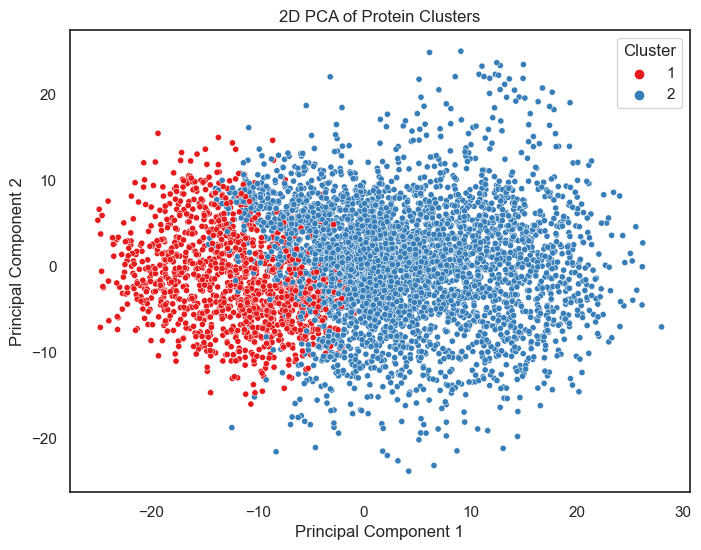

In [19]:
from sklearn.decomposition import PCA

# Compute PCA on the cleaned data, reducing to 2 dimensions
clusters = sch.fcluster(row_linkage, 2 , criterion="maxclust")
pca = PCA(n_components=2)
pca_result = pca.fit_transform(pearson_clean.values)

# Create a DataFrame for the PCA results
pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=pearson_clean.index)
pca_df["Cluster"] = clusters  # Add the cluster assignments

# Plot the clusters in 2D using a scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Cluster", palette="Set1", s=20)
plt.title("2D PCA of Protein Clusters")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.show()


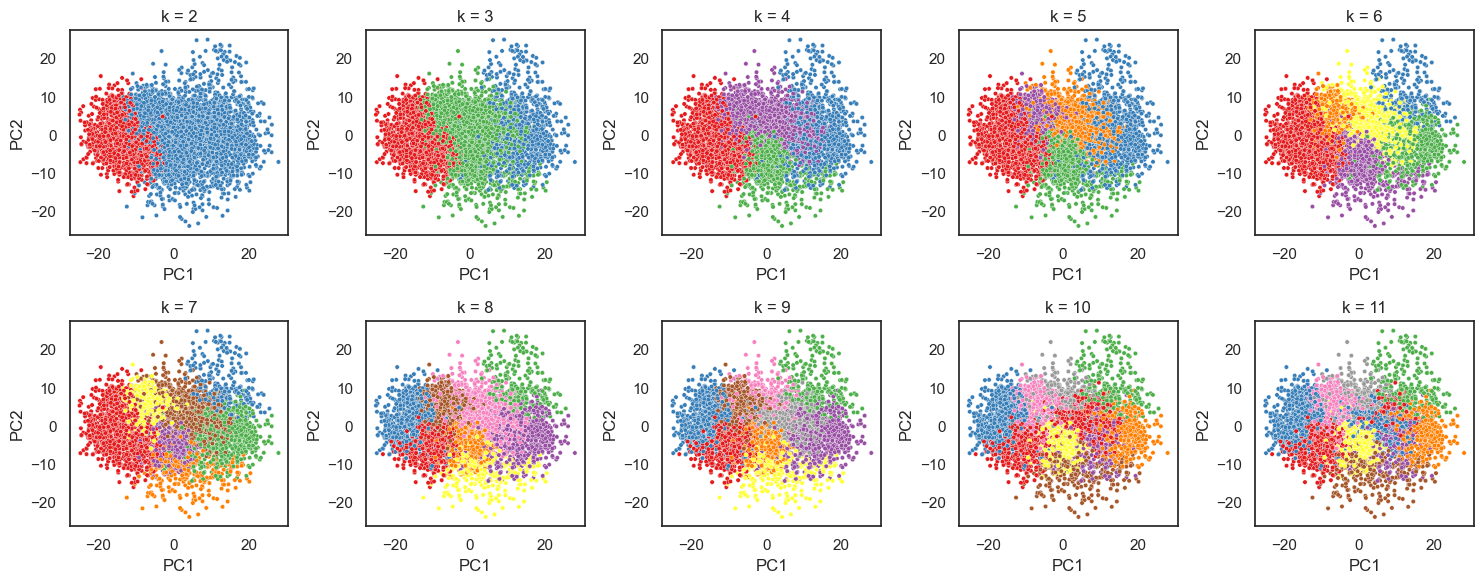

In [20]:
# Create a 2x5 grid for plots with a reduced overall figure size
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()  # flatten to easily iterate over

# Loop over cluster numbers from 2 to 10
for i, k in enumerate(range(2, 12)):
    # Compute clusters using hierarchical clustering
    clusters = sch.fcluster(row_linkage, k, criterion="maxclust")
    
    # Perform PCA on the cleaned data
    pca = PCA(n_components=2)
    pca_result = pca.fit_transform(pearson_clean.values)
    
    # Create DataFrame for PCA results with cluster assignments
    pca_df = pd.DataFrame(pca_result, columns=["PC1", "PC2"], index=pearson_clean.index)
    pca_df["Cluster"] = clusters
    
    # Plot on the corresponding axis
    ax = axes[i]
    sns.scatterplot(
        data=pca_df, 
        x="PC1", 
        y="PC2", 
        hue="Cluster", 
        palette="Set1", 
        s=10, 
        ax=ax,
        legend=False  # Disable legend for individual subplots
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.show()

save 3 clusters

In [ ]:
cluster_labels = fcluster(row_linkage, 3, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_3.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters_3.csv'.")


Protein Clusters:
     Protein  Cluster
0        A2M        3
1       AAAS        3
2       AACS        3
3      AAGAB        1
4       AAK1        2
...      ...      ...
5108  ZRANB2        1
5109    ZW10        3
5110  ZWILCH        1
5111     ZYX        3
5112    ZZZ3        3

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters_3.csv'.


save 4 clusters

In [25]:

cluster_labels = fcluster(row_linkage, 4, criterion='maxclust')

# Create a DataFrame mapping each protein to its cluster.
clusters_df = pd.DataFrame({
    'Protein': pearson_clean.index,
    'Cluster': cluster_labels
})

print("\nProtein Clusters:")
print(clusters_df)

# Save the cluster assignments to a CSV file.
clusters_df.to_csv("protein_clusters_4.csv", index=False)
print("\nCluster assignments saved to 'protein_clusters_4.csv'.")


Protein Clusters:
     Protein  Cluster
0        A2M        3
1       AAAS        4
2       AACS        3
3      AAGAB        1
4       AAK1        2
...      ...      ...
5108  ZRANB2        1
5109    ZW10        3
5110  ZWILCH        1
5111     ZYX        3
5112    ZZZ3        4

[5113 rows x 2 columns]

Cluster assignments saved to 'protein_clusters_4.csv'.


#### Statistical analysis of clusters

In [21]:

# Set a threshold for average gene correlation (example threshold: 0.5)
threshold = 0.1

# Create a copy of your data and add the cluster labels
data = pearson_clean.copy()
data["Cluster"] = clusters  # clusters should align with the rows of pearson_clean

# Dictionary to store summary statistics for each cluster
cluster_stats = {}

# Loop over each cluster
for cluster_label, group in data.groupby("Cluster"):
    # Remove the cluster column so that only gene correlation values remain
    group_data = group.drop(columns=["Cluster"])
    
    # Compute gene-wise statistics for the proteins in this cluster
    gene_means = group_data.mean(axis=0)
    gene_vars = group_data.var(axis=0)
    gene_min = group_data.min(axis=0)
    gene_max = group_data.max(axis=0)
    
    # Aggregate these gene-level stats to get cluster-level summary measures.
    # For example, we compute the average of the gene means, standard deviation, etc.
    cluster_summary = {
        "mean_of_gene_means": gene_means.mean(),
        "std_of_gene_means": gene_means.std(),
        "mean_of_gene_vars": gene_vars.mean(),
        "std_of_gene_vars": gene_vars.std(),
        "average_min": gene_min.mean(),
        "average_max": gene_max.mean(),
        "num_genes_above_threshold": (gene_means > threshold).sum(),
        "total_genes": len(gene_means)
    }
    
    cluster_stats[cluster_label] = cluster_summary

# Convert the dictionary to a DataFrame for easier viewing
stats_df = pd.DataFrame(cluster_stats).T
stats_df.index.name = "Cluster"
print(stats_df)


         mean_of_gene_means  std_of_gene_means  mean_of_gene_vars  \
Cluster                                                             
1                  0.017470           0.066884           0.004437   
2                  0.007568           0.093284           0.005479   
3                 -0.016192           0.106489           0.006252   
4                 -0.003981           0.064767           0.005940   
5                 -0.002556           0.104387           0.005454   
6                  0.005001           0.028650           0.004316   
7                  0.020646           0.076827           0.006710   
8                  0.005451           0.054701           0.004148   
9                 -0.011281           0.043307           0.005333   
10                -0.017904           0.060361           0.003839   
11                 0.003121           0.034858           0.004530   

         std_of_gene_vars  average_min  average_max  \
Cluster                                        

3 clusters

In [22]:
clusters = sch.fcluster(row_linkage, 3, criterion="maxclust")


In [23]:
threshold = 0.1

# Create a copy of your data and add the cluster labels
data = pearson_clean.copy()
data["Cluster"] = clusters  # clusters should align with the rows of pearson_clean

# Dictionary to store summary statistics for each cluster
cluster_stats = {}

# Loop over each cluster
for cluster_label, group in data.groupby("Cluster"):
    # Remove the cluster column so that only gene correlation values remain
    group_data = group.drop(columns=["Cluster"])
    
    # Compute gene-wise statistics for the proteins in this cluster
    gene_means = group_data.mean(axis=0)
    gene_vars = group_data.var(axis=0)
    gene_min = group_data.min(axis=0)
    gene_max = group_data.max(axis=0)
    
    # Aggregate these gene-level stats to get cluster-level summary measures.
    # For example, we compute the average of the gene means, standard deviation, etc.
    cluster_summary = {
        "mean_of_gene_means": gene_means.mean(),
        "std_of_gene_means": gene_means.std(),
        "mean_of_gene_vars": gene_vars.mean(),
        "std_of_gene_vars": gene_vars.std(),
        "average_min": gene_min.mean(),
        "average_max": gene_max.mean(),
        "num_genes_above_threshold": (gene_means > threshold).sum(),
        "total_genes": len(gene_means)
    }
    
    cluster_stats[cluster_label] = cluster_summary

# Convert the dictionary to a DataFrame for easier viewing
stats_df = pd.DataFrame(cluster_stats).T
stats_df.index.name = "Cluster"
print(stats_df)


         mean_of_gene_means  std_of_gene_means  mean_of_gene_vars  \
Cluster                                                             
1                  0.012453           0.075977           0.005829   
2                 -0.006849           0.083573           0.007693   
3                  0.002207           0.015154           0.006847   

         std_of_gene_vars  average_min  average_max  \
Cluster                                               
1                0.003642    -0.219125     0.268291   
2                0.005268    -0.263099     0.267033   
3                0.004870    -0.284662     0.334876   

         num_genes_above_threshold  total_genes  
Cluster                                          
1                           3251.0      25976.0  
2                           2534.0      25976.0  
3                              0.0      25976.0  


#### Other analyses, not ran

In [ ]:
import scipy.cluster.hierarchy as sch
from scipy.spatial.distance import pdist, squareform
from sklearn.metrics import pairwise_distances
import networkx as nx

# ----- 1. Distribution Plots of Correlation Values ----- #

# (a) Violin Plot: Distribution of all protein–gene correlations per cluster.
# Add the cluster labels to the data:
data = pearson_clean.copy()
data['Cluster'] = clusters

# Melt the data so each row is one protein-gene correlation value
data_melted = data.reset_index().melt(id_vars=['index', 'Cluster'], var_name='Gene', value_name='Correlation')
data_melted.rename(columns={'index': 'Protein'}, inplace=True)

plt.figure(figsize=(10,6))
sns.violinplot(data=data_melted, x='Cluster', y='Correlation', palette='Set1')
plt.title("Violin Plot of Protein-Gene Correlation Values per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Correlation")
plt.tight_layout()
plt.show()


# (b) Histogram/Density Plot: Distribution of average gene correlations in each cluster.
# For each cluster, compute the average correlation per gene.
cluster_averages = data.groupby('Cluster').mean().drop(columns=['Cluster'], errors='ignore')
# Melt the cluster averages (each row: one gene in one cluster, with its average correlation)
cluster_avg_melted = cluster_averages.reset_index().melt(id_vars='Cluster', var_name='Gene', value_name='Avg_Correlation')

plt.figure(figsize=(10,6))
sns.histplot(data=cluster_avg_melted, x='Avg_Correlation', hue='Cluster', palette='Set1', kde=True, element='step')
plt.title("Histogram/Density of Average Gene Correlations per Cluster")
plt.xlabel("Average Correlation")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


# ----- 2. Cluster-Level “Profiles” ----- #

# Compute the centroid (average profile) for each cluster (across genes)
centroids = data.groupby('Cluster').mean().drop(columns=['Cluster'], errors='ignore')
print("Cluster Centroids (Average Profiles):")
print(centroids)

# Compare centroids between clusters:
# (a) Compute pairwise correlation between centroids (transposing so genes are observations)
centroid_corr = centroids.T.corr()
print("\nCorrelation between Cluster Centroids:")
print(centroid_corr)

plt.figure(figsize=(6,4))
sns.heatmap(centroid_corr, annot=True, cmap='coolwarm')
plt.title("Heatmap: Correlation between Cluster Centroids")
plt.tight_layout()
plt.show()

# (b) Compute Euclidean distances between centroids
from scipy.spatial.distance import pdist, squareform
centroid_dist = pd.DataFrame(squareform(pdist(centroids)), index=centroids.index, columns=centroids.index)
print("\nEuclidean distances between Cluster Centroids:")
print(centroid_dist)


# ----- 3. Correlation Network Analysis ----- #

# Build a network where nodes are proteins and an edge exists if the similarity between their gene correlation profiles is high.
# Here, compute the protein–protein correlation matrix using the rows of pearson_clean.
protein_corr = pearson_clean.T.corr()  # proteins x proteins

# Set a correlation threshold for connecting nodes (adjust as needed)
corr_threshold = 0.7

# Create an undirected graph
G = nx.Graph()

# Map each protein (row) to its cluster label
protein_cluster_mapping = dict(zip(pearson_clean.index, clusters))

# Add nodes with cluster attribute
for protein in protein_corr.index:
    G.add_node(protein, cluster=protein_cluster_mapping[protein])

# Add edges between proteins with correlation above the threshold
for i, protein_i in enumerate(protein_corr.index):
    for j, protein_j in enumerate(protein_corr.columns):
        if i < j and protein_corr.loc[protein_i, protein_j] > corr_threshold:
            G.add_edge(protein_i, protein_j, weight=protein_corr.loc[protein_i, protein_j])

# Compute network density
density = nx.density(G)
print("\nNetwork Density:", density)

# For modularity, we can use the community_louvain package (install via pip install python-louvain) 
try:
    import community as community_louvain
    partition = community_louvain.best_partition(G)
    modularity = community_louvain.modularity(partition, G)
    print("Network Modularity:", modularity)
except ImportError:
    print("community_louvain not installed; skipping modularity calculation.")

# Identify hub proteins (top 5 by degree centrality)
degree_centrality = nx.degree_centrality(G)
sorted_hubs = sorted(degree_centrality.items(), key=lambda x: x[1], reverse=True)
print("\nTop 5 Hub Proteins (by Degree Centrality):")
for protein, centrality in sorted_hubs[:5]:
    print(f"{protein}: {centrality:.4f}")

# Optionally, visualize the network (this can be messy for large networks)
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G, seed=42)  # positions for all nodes
node_colors = [G.nodes[node]['cluster'] for node in G.nodes()]
nx.draw_networkx_nodes(G, pos, node_size=50, cmap=plt.cm.Set1, node_color=node_colors)
nx.draw_networkx_edges(G, pos, alpha=0.3)
plt.title("Protein Correlation Network (Edges with r > {:.2f})".format(corr_threshold))
plt.axis("off")
plt.tight_layout()
plt.show()


# Spearman

In [34]:
spearman = load('data/full_spearman.joblib')
spearman

,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1,A2ML1,A4GALT,AAAS,AACS,AACSP1,...,ZWILCH,ZWINT,ZXDA,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3
proteins,,,,,,,,,,,,,,,,,,,,,
A2M,0.259988,0.233929,-0.116902,0.230195,0.000000,-0.142924,0.000000,0.000000,0.000000,0.0,...,0.139395,0.000000,0.000000,0.000000,0.000000,0.000000,0.225174,0.170703,0.000000,0.123180
AAAS,0.000000,0.000000,0.000000,0.000000,0.121819,0.111012,0.000000,0.000000,-0.166863,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.109546,0.000000,0.000000,-0.127864,0.114503
AACS,0.000000,0.000000,0.000000,0.000000,0.000000,-0.147828,0.000000,0.000000,0.446383,0.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
AAGAB,0.127329,0.103151,0.000000,0.000000,0.000000,-0.157370,-0.153830,0.197541,0.120025,0.0,...,0.218814,0.000000,0.117859,0.117173,0.000000,0.000000,0.000000,0.000000,0.209716,0.000000
AAK1,0.182794,0.179434,0.000000,0.000000,0.000000,-0.114290,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.144951,0.000000,0.000000,0.000000,0.239220,0.291094,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RUVBL2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.106743,-0.106265,0.0,...,0.000000,0.000000,0.000000,0.000000,0.150135,0.000000,0.000000,0.000000,0.000000,0.000000
RYBP,0.106975,0.000000,0.000000,0.000000,0.000000,0.000000,-0.208265,0.189727,0.000000,0.0,...,0.000000,0.183956,0.000000,0.000000,0.218500,0.000000,0.000000,-0.125549,0.156089,0.000000
S100A10,-0.295469,-0.275389,0.129749,-0.177183,0.000000,0.120204,0.359290,-0.332902,0.000000,0.0,...,0.000000,-0.147222,0.000000,0.000000,-0.194365,0.000000,0.000000,0.235213,-0.181334,0.000000


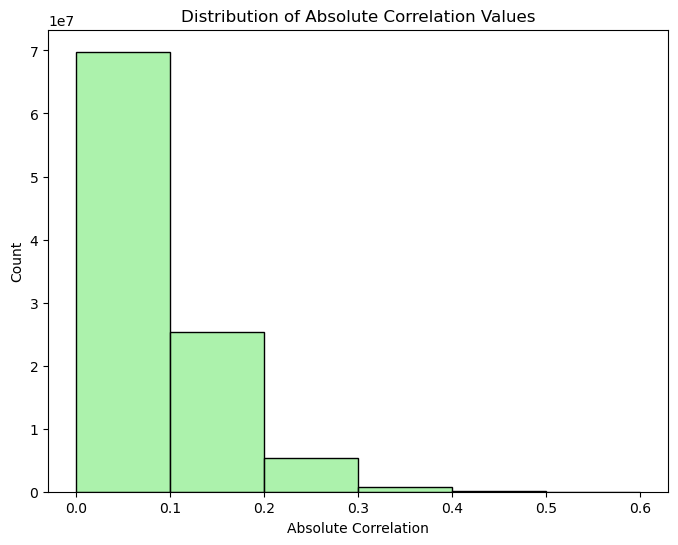

In [35]:
abs_values = spearman.abs().values.flatten()

#bins (0–0.1, 0.1–0.2, 0.2–0.3, ..., 0.9)
bins = np.arange(0, 0.7, 0.1)

plt.figure(figsize=(8, 6))
sns.histplot(abs_values, bins=bins, kde=False, color='lightgreen', edgecolor='black')
plt.xlabel('Absolute Correlation')
plt.ylabel('Count')
plt.title('Distribution of Absolute Correlation Values')
plt.xticks(bins)  # Ensure the x-axis shows the bin edges
plt.show()


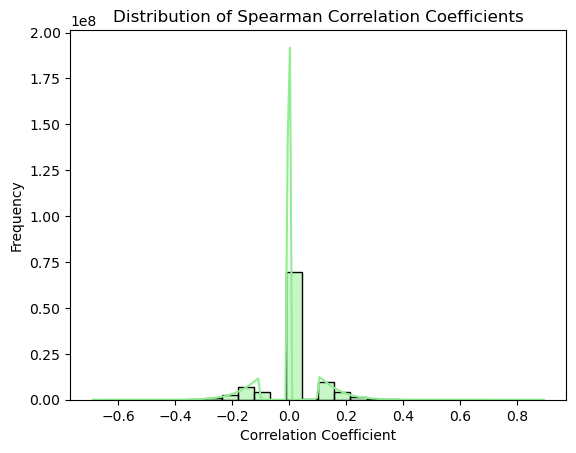

In [50]:
data = spearman.values.flatten()

# Create a histogram with a kernel density estimate (KDE) in skyblue
sns.histplot(data, color='lightgreen', kde=True)

# Optional customizations
plt.title("Distribution of Spearman Correlation Coefficients")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")

# Display the plot
plt.show()

filter out zeros

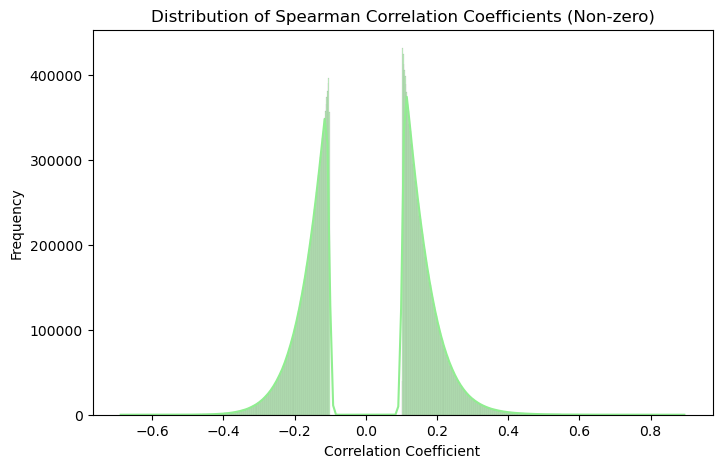

In [52]:
# Filter out exact zeros or near-zeros
non_zero_data = data[np.isclose(data, 0, atol=1e-10) == False]

plt.figure(figsize=(8, 5))
sns.histplot(non_zero_data, color='lightgreen', kde=True)
plt.title("Distribution of Spearman Correlation Coefficients (Non-zero)")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Frequency")
plt.show()

### Plot protein - # correlated genes

how many zeros


In [36]:
zero_counts = (spearman == 0).sum(axis=1)

# Compute the number of genes correlated above thresholds
thresholds = [0.1, 0.2, 0.3]
thresh_counts = {t: (spearman.abs() > t).sum(axis=1) for t in thresholds}

In [37]:
print_summary()

          Zero Correlations  Correlated > 0.1  Correlated > 0.2  \
proteins                                                          
A2M                   15713             10282              2847   
AAAS                  21163              4832               240   
AACS                  22157              3838               121   
AAGAB                 17925              8070               872   
AAK1                  15616             10379              2799   
...                     ...               ...               ...   
RUVBL2                21625              4370               155   
RYBP                  15113             10882              2730   
S100A10               11266             14729              6753   
S100A11               14069             11926              3535   
S100A13               16522              9473              1810   

          Correlated > 0.3  
proteins                    
A2M                    372  
AAAS                     0  
AACS        

The following histogram displays how many genes per protein have correlations above 0.1 (absolute value). It helps to understand whether most genes have weak or strong correlations with each protein.

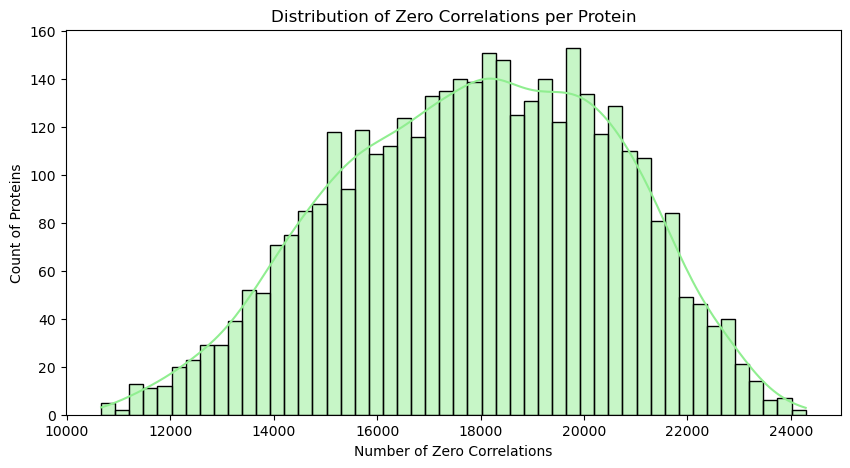

In [38]:
# Cell 1: Plot histogram of zero counts
plt.figure(figsize=(10, 5))
sns.histplot(zero_counts, bins=50, color ="lightgreen", kde=True)
plt.xlabel("Number of Zero Correlations")
plt.ylabel("Count of Proteins")
plt.title("Distribution of Zero Correlations per Protein")
plt.show()

## Above 0.1 absolute correlation

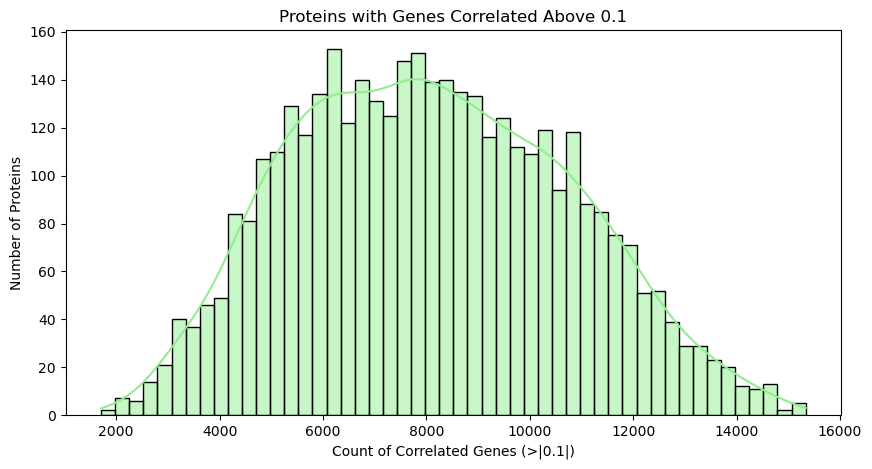

In [39]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.1], bins=50, color ="lightgreen", kde=True)
plt.xlabel("Count of Correlated Genes (>|0.1|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.1")
plt.show()

## Above 0.2 absolute correlation

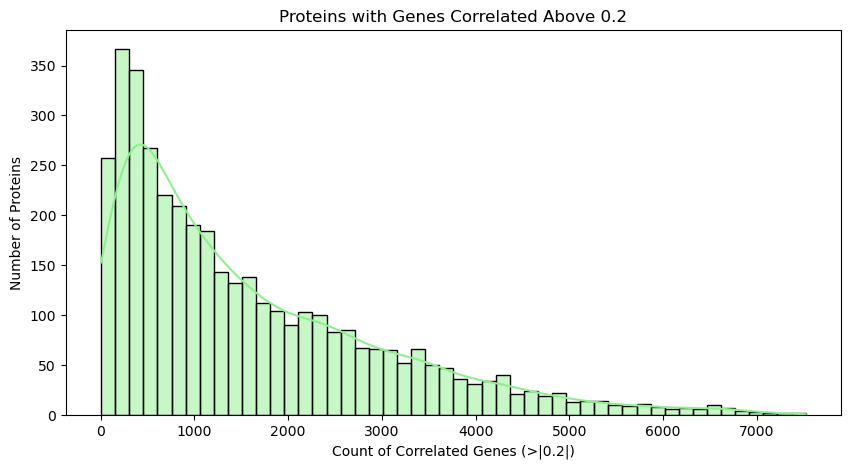

In [40]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.2], bins=50,color ="lightgreen",  kde=True)
plt.xlabel("Count of Correlated Genes (>|0.2|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.2")
plt.show()

## Above 0.3 absolute correlation

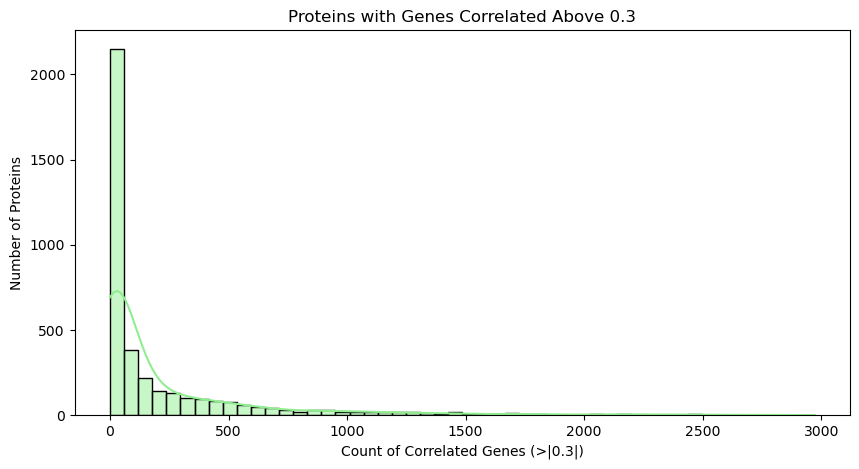

In [41]:
plt.figure(figsize=(10, 5))
sns.histplot(thresh_counts[0.3], bins=50,color ="lightgreen",  kde=True)
plt.xlabel("Count of Correlated Genes (>|0.3|)")
plt.ylabel("Number of Proteins")
plt.title("Proteins with Genes Correlated Above 0.3")
plt.show()